# 02 — Preparação do conjunto de Bristol (canal ambiental, ramo LSTM)

Dissertação: *Monitoramento multimodal baseado em TinyML para diagnóstico preditivo em data centers*.

Este notebook prepara o canal ambiental do pré-treinamento (seção 3.3.1):

1. lê os CSV de Bristol (formato longo `Time, DeviceId, Sensor, Value`) e mantém só **temperatura, umidade e pressão**, as variáveis equivalentes às do BME280;
2. monta, para cada dispositivo, uma **grade regular de 10 s**; lacunas de até 20 s são interpoladas, e lacunas maiores interrompem a série;
3. divide **70/15/15 em blocos cronológicos**, com os mesmos instantes de corte para todos os dispositivos;
4. forma **janelas de 30 passos (5 min)** sem sobreposição, sempre dentro de um trecho contínuo e de uma única partição;
5. rotula cada janela pela **regra térmica da Figura 3**, aplicada à temperatura do último passo;
6. acrescenta **derivas sintéticas**: rampas de temperatura com início, forma e intensidade variáveis, nas quais a umidade relativa cai como em um aquecimento real;
7. normaliza com **limites físicos fixos**, os mesmos que o firmware vai usar, e salva tudo no Google Drive.

**Ambiente:** CPU.

In [1]:
# 1. Ambiente e caminhos
import sys, os, json, platform, numpy as np, pandas as pd
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__)
from google.colab import drive
drive.mount("/content/drive")

PASTA_CSV = "/content/drive/MyDrive/dissertacao_tinyml/bristol"          # onde estão os CSV de Bristol
PASTA     = "/content/drive/MyDrive/dissertacao_tinyml/bristol_preparado" # saída
os.makedirs(PASTA, exist_ok=True)
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

Python 3.13.16 | NumPy 2.1.3 | pandas 2.2.3
Mounted at /content/drive


In [2]:
# 2. Funções (parâmetros idênticos aos do firmware)
# ===== Preparação do conjunto de Bristol (Erol et al., 2023) para o ramo LSTM =====
import glob, os
import numpy as np
import pandas as pd

PASSO_S     = 10                 # resolução do conjunto e do passo do LSTM (média de 5 leituras de 2 s no protótipo)
N_PASSOS    = 30                 # janela de 30 passos = 5 min
STRIDE      = 30                 # janelas sem sobreposição (evita redundância e vazamento entre janelas vizinhas)
MAX_LACUNA  = 2                  # interpola no máximo 2 passos (20 s) faltantes; lacunas maiores quebram o trecho
SENSORES    = {"Temperature": "temp", "Humidity": "umid", "Pressure": "press"}
LIMITES     = (27.0, 32.0, 35.0) # regra da Figura 3 (nível térmico); nível acústico = 0 neste conjunto
HORIZONTE   = 0                  # 0 = rótulo pelo estado no último passo da janela (diagnóstico)

# Normalização min-max com limites físicos fixos (iguais no firmware), com saturação
FAIXAS = {"temp": (10.0, 45.0), "umid": (0.0, 100.0), "dpress": (-5.0, 5.0)}

def classe_termica(t):
    t = np.asarray(t)
    return np.select([t > LIMITES[2], t > LIMITES[1], t > LIMITES[0]], [3, 2, 1], 0).astype(np.int8)

def ler_bristol(pasta):
    """Lê todos os CSV (formato longo: Time, DeviceId, Sensor, Value), só T, U e P."""
    partes = []
    for arq in sorted(glob.glob(os.path.join(pasta, "**", "*.csv"), recursive=True)):
        for bloco in pd.read_csv(arq, usecols=["Time", "DeviceId", "Sensor", "Value"],
                                 dtype={"Time": "int64", "DeviceId": "category", "Sensor": "category",
                                        "Value": "float32"}, chunksize=5_000_000):
            bloco = bloco[bloco["Sensor"].isin(SENSORES.keys())]
            partes.append(bloco)
    df = pd.concat(partes, ignore_index=True)
    df["Sensor"] = df["Sensor"].astype(str).map(SENSORES)
    df["DeviceId"] = df["DeviceId"].astype(str)
    return df

def grade_regular(df):
    """Por dispositivo: grade de 10 s, média por intervalo, interpolação de lacunas curtas,
    pressão em hPa. Retorna {dispositivo: DataFrame com temp, umid, press e coluna 'trecho'}."""
    saida = {}
    for disp, d in df.groupby("DeviceId"):
        w = d.pivot_table(index="Time", columns="Sensor", values="Value", aggfunc="mean")
        w.index = pd.to_datetime(w.index, unit="s", utc=True)
        w = w.resample(f"{PASSO_S}s").mean()
        w = w.interpolate(limit=MAX_LACUNA, limit_area="inside")
        w["press"] = w["press"] / 100.0                       # Pa -> hPa
        valido = w[["temp", "umid", "press"]].notna().all(axis=1)
        w["trecho"] = (~valido).cumsum()                       # novo trecho a cada lacuna longa
        saida[disp] = w[valido]
    return saida

def cortes_cronologicos(grades, frac=(0.70, 0.15, 0.15)):
    """Instantes de corte comuns a todos os dispositivos (blocos cronológicos)."""
    ini = min(g.index.min() for g in grades.values()); fim = max(g.index.max() for g in grades.values())
    dur = fim - ini
    return ini + dur * frac[0], ini + dur * (frac[0] + frac[1])

def particao_de(ts, c1, c2):
    return "treino" if ts < c1 else ("validacao" if ts < c2 else "teste")

def janelas_dispositivo(g, c1, c2):
    """Janelas de 30 passos dentro de trechos contínuos e de uma única partição."""
    out = []
    g = g.copy()
    g["part"] = np.where(g.index < c1, "treino", np.where(g.index < c2, "validacao", "teste"))
    for (_, part), seg in g.groupby(["trecho", "part"]):
        v = seg[["temp", "umid", "press"]].to_numpy(np.float32)
        for i in range(0, len(v) - N_PASSOS - HORIZONTE + 1, STRIDE):
            out.append((part, v[i:i + N_PASSOS], v[i + N_PASSOS - 1 + HORIZONTE, 0], seg.index[i]))
    return out

# ----- Derivas sintéticas (rampas de temperatura) -----
def pressao_vapor_sat(t):            # Magnus (hPa)
    return 6.112 * np.exp(17.62 * t / (243.12 + t))

def aplicar_deriva(v, alvo, rng):
    """Sobrepõe uma rampa de temperatura à janela v (30 x 3) até a temperatura 'alvo' no fim,
    com início e inclinação aleatórios; a umidade relativa cai como em aquecimento real
    (umidade absoluta constante). A pressão não é alterada."""
    v = v.copy()
    t0 = v[:, 0]
    inicio = rng.integers(0, N_PASSOS - 5)                 # a rampa começa entre o passo 0 e o 24
    perfil = np.zeros(N_PASSOS, np.float32)
    n = N_PASSOS - inicio
    forma = rng.choice(["linear", "suave"])
    x = np.linspace(0, 1, n, dtype=np.float32)
    perfil[inicio:] = x if forma == "linear" else (1 - np.cos(np.pi * x)) / 2
    delta = (alvo - t0[-1]) * perfil
    t_novo = t0 + delta
    v[:, 1] = np.clip(v[:, 1] * pressao_vapor_sat(t0) / pressao_vapor_sat(t_novo), 0, 100)
    v[:, 0] = t_novo
    return v

ALVOS = {0: (25.0, 27.0), 1: (27.3, 32.0), 2: (32.3, 35.0), 3: (35.3, 42.0)}   # faixas de temperatura final

def gerar_sinteticas(janelas_base, n_por_classe, rng):
    """Para cada classe (inclusive 'rampa que não chega a Atenção'), gera n janelas com deriva."""
    X, y = [], []
    for c, (lo, hi) in ALVOS.items():
        idx = rng.integers(0, len(janelas_base), n_por_classe)
        for i in idx:
            alvo = rng.uniform(lo, hi)
            base = janelas_base[i]
            if c == 0 and alvo <= base[-1, 0]:           # rampa sub-limiar precisa subir
                alvo = min(27.0, base[-1, 0] + rng.uniform(0.5, 2.0))
            w = aplicar_deriva(base, alvo, rng)
            X.append(w); y.append(int(classe_termica(w[-1, 0])))
    return np.stack(X), np.array(y, np.int8)

# ----- Atributos de entrada (idênticos no firmware) -----
def atributos(v):
    """(n, 30, 3) [temp, umid, press] -> (n, 30, 3) [temp, umid, dpress] normalizados em [0, 1].
    dpress = pressão menos a média da janela: remove a diferença de altitude (Bristol ~ nível do mar,
    São Paulo ~ 760 m) e preserva a dinâmica."""
    v = np.asarray(v, np.float32)
    dp = v[..., 2] - v[..., 2].mean(axis=-1, keepdims=True)
    cols = [v[..., 0], v[..., 1], dp]
    out = [np.clip((c - lo) / (hi - lo), 0, 1) for c, (lo, hi) in zip(cols, FAIXAS.values())]
    return np.stack(out, axis=-1).astype(np.float32)


In [3]:
# 3. Leitura e inventário
bruto = ler_bristol(PASTA_CSV)
print(f"{len(bruto):,} leituras de T/U/P | dispositivos: {sorted(bruto.DeviceId.unique())}")
ini, fim = pd.to_datetime(bruto.Time.min(), unit="s"), pd.to_datetime(bruto.Time.max(), unit="s")
print("Período:", ini, "→", fim)
inv = bruto.pivot_table(index="DeviceId", columns="Sensor", values="Value",
                        aggfunc=["count", "min", "max"]).round(2)
display(inv); inv.to_csv(f"{PASTA}/inventario_bristol.csv")

29,745,210 leituras de T/U/P | dispositivos: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Período: 2022-02-11 13:45:53 → 2022-07-24 23:51:20


count                        min                             max  \
Sensor      press     temp     umid    press       temp       umid     press   
DeviceId                                                                       
A         1287930  1287930  1287930  97846.0  18.980000  20.410000  103757.0   
B         1173171  1173171  1173171  97795.0  19.360001  18.360001  103719.0   
C         1298089  1298089  1298089  97861.0  17.090000  14.710000  103772.0   
D         1306542  1306542  1306542  97864.0  16.780001   8.260000  103777.0   
E         1306240  1306240  1306240  97849.0  16.799999  15.550000  103754.0   
F         1254235  1254235  1254235  97880.0  15.160000  17.660000  103795.0   
G         1237735  1237735  1237735  97863.0  18.139999  19.570000  103783.0   
H         1051128  1051128  1051128  97848.0  19.540001  17.920000  103767.0   

                                
Sensor         temp       umid  
DeviceId                        
A         28.780001  60.439999  
B         29.580000  64.889999  
C         40.320000  60.570000  
D         46.840000  67.529999  
E         29.820000  64.650002  
F         33.599998  61.099998  
G         29.139999  66.320000  
H         29.120001  53.619999

In [4]:
# 4. Grade regular de 10 s por dispositivo
grades = grade_regular(bruto); del bruto
resumo = pd.DataFrame({d: {"passos_validos": len(g), "trechos_continuos": g.trecho.nunique(),
                           "temp_min": g.temp.min(), "temp_max": g.temp.max(),
                           "% passos > 27 °C": 100 * (g.temp > 27).mean()} for d, g in grades.items()}).T
display(resumo.round(2)); resumo.to_csv(f"{PASTA}/resumo_grade.csv")
print("Os dados reais quase não passam de 27 °C: as classes de anomalia vêm das derivas sintéticas.")

,passos_validos,trechos_continuos,temp_min,temp_max,% passos > 27 °C
A,1293726.0,480.0,18.99,28.78,0.62
B,1187026.0,3644.0,19.35,29.58,1.81
C,1303636.0,464.0,17.09,40.33,2.68
D,1308722.0,40.0,16.77,46.85,1.63
E,1308563.0,62.0,16.80,29.82,0.86
F,1259960.0,602.0,15.15,33.60,1.37
G,1244767.0,877.0,18.15,29.15,1.07
H,827063.0,2269.0,19.53,29.12,0.73


Os dados reais quase não passam de 27 °C: as classes de anomalia vêm das derivas sintéticas.


In [5]:
# 5. Divisão cronológica e janelas de 30 passos
c1, c2 = cortes_cronologicos(grades)
print("Cortes: treino até", c1, "| validação até", c2, "| teste depois")
J = []
for d, g in grades.items():
    J.extend(janelas_dispositivo(g, c1, c2))
base = {p: np.stack([j[1] for j in J if j[0] == p]) for p in ["treino", "validacao", "teste"]}
rot_base = {p: np.array([classe_termica(j[2]) for j in J if j[0] == p], np.int8) for p in base}
for p in base:
    print(f"{p:10s} {base[p].shape}  classes reais: {np.bincount(rot_base[p], minlength=4)}")

Cortes: treino até 2022-06-05 23:13:41+00:00 | validação até 2022-06-30 11:32:30.500000+00:00 | teste depois
treino     (235883, 30, 3)  classes reais: [235289    442    107     45]
validacao  (37647, 30, 3)  classes reais: [37574    63     9     1]
teste      (47557, 30, 3)  classes reais: [43924  3518    63    52]


In [6]:
# 6. Derivas sintéticas, geradas dentro de cada partição (sem vazamento)
FRAC_SINT = 0.10   # por classe, em relação ao número de janelas reais da partição
dados = {}
for p in base:
    n = max(1, int(FRAC_SINT * len(base[p])))
    Xs, ys = gerar_sinteticas(base[p], n, rng)
    Xb = np.concatenate([base[p], Xs]); yb = np.concatenate([rot_base[p], ys])
    sint = np.concatenate([np.zeros(len(base[p]), bool), np.ones(len(Xs), bool)])
    ordem = rng.permutation(len(yb))
    dados[p] = (Xb[ordem], yb[ordem], sint[ordem])
tab = pd.DataFrame({p: np.bincount(d[1], minlength=4) for p, d in dados.items()},
                   index=["Normal", "Atenção", "Crítico", "Falha"]).T
display(tab); tab.to_csv(f"{PASTA}/distribuicao_classes.csv")

,Normal,Atenção,Crítico,Falha
treino,258877,24030,23695,23633
validacao,41338,3827,3773,3765
teste,48679,8273,4818,4807


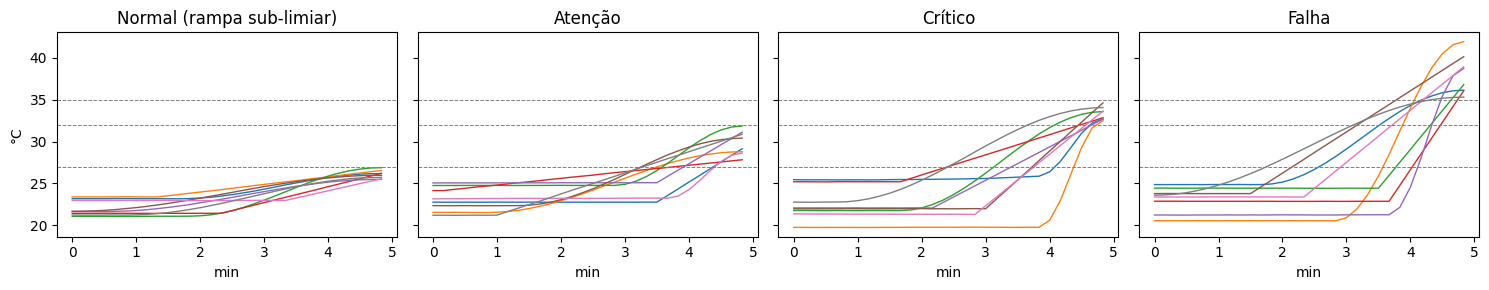

In [7]:
# 7. Exemplos de janelas sintéticas por classe (conferência visual)
import matplotlib.pyplot as plt
Xtr, ytr, str_ = dados["treino"]
fig, eixos = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
nomes = ["Normal (rampa sub-limiar)", "Atenção", "Crítico", "Falha"]
for c, ax in enumerate(eixos):
    for w in Xtr[(ytr == c) & str_][:8]:
        ax.plot(np.arange(N_PASSOS) * PASSO_S / 60, w[:, 0], lw=1)
    for lim in LIMITES: ax.axhline(lim, ls="--", c="gray", lw=.7)
    ax.set_title(nomes[c]); ax.set_xlabel("min")
eixos[0].set_ylabel("°C"); plt.tight_layout(); plt.show()

In [8]:
# 8. Atributos normalizados e gravação
for p, (X, y, s) in dados.items():
    np.savez(f"{PASTA}/{p}.npz", X=atributos(X), X_bruto=X, y=y, sintetica=s)
    print(f"{p:10s} X={atributos(X[:1]).shape[1:]}  n={len(y)}")
params = {"passo_s": PASSO_S, "n_passos": N_PASSOS, "stride": STRIDE, "max_lacuna_passos": MAX_LACUNA,
          "atributos": ["temp", "umid", "dpress (pressão - média da janela)"],
          "faixas_minmax": FAIXAS, "limites_termicos": LIMITES, "horizonte": HORIZONTE,
          "frac_sinteticas_por_classe": FRAC_SINT, "alvos_derivas": {str(k): v for k, v in ALVOS.items()},
          "cortes": [str(c1), str(c2)], "semente": SEMENTE,
          "versoes": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__}}
json.dump(params, open(f"{PASTA}/params_bristol.json", "w"), indent=2, ensure_ascii=False)
print("Parâmetros salvos.")

treino     X=(30, 3)  n=330235
validacao  X=(30, 3)  n=52703
teste      X=(30, 3)  n=66577
Parâmetros salvos.


## Resultado

No Drive, em `dissertacao_tinyml/bristol_preparado/`:

| Arquivo | Conteúdo |
|---|---|
| `treino.npz`, `validacao.npz`, `teste.npz` | `X` (n, 30, 3) normalizado, `X_bruto` (°C, %, hPa), `y` (0 a 3), `sintetica` (bool) |
| `inventario_bristol.csv`, `resumo_grade.csv`, `distribuicao_classes.csv` | rastreabilidade e tabelas para a dissertação |
| `params_bristol.json` | parâmetros de janela, normalização e derivas (guia de replicação e firmware) |

**Próximos notebooks:** `03_treino_cnn.ipynb` e `04_treino_lstm.ipynb`.